# Saudi Nomu parallel market: validating and comparing listing valuations
**Context.** Nomu is the Saudi Exchange's parallel market for smaller companies, with lighter listing requirements than the main market (TASI). This table of 18 Nomu listings (income, shares, EPS, P/E, share price and market cap, with each company's financial advisor) was compiled from public listing announcements for a talk on going public. Figures are in SAR millions (income, shares, market cap) and SAR (price, EPS), as compiled at the time.

**What this shows.** Before comparing valuations, check that the table is *internally consistent*: P/E should equal price ÷ EPS, market cap should equal price × shares, and EPS should equal income ÷ shares. Then compare valuations across companies and advisors.

In [1]:
import warnings, pathlib, os
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
n = pd.read_csv("data/nomu_listings.csv", encoding="utf-8-sig")
n.columns = ["company", "advisor", "income_m", "shares_m", "eps", "eps_2", "pe", "price", "mcap_m"]
n["advisor"] = n.advisor.str.strip().str.replace(r"\s+", " ", regex=True).replace({"Aldukheil Financial Group": "Al Dukheil Financial Group", "Kasb Group": "KASB Capital"})
n["pe_check"] = n.price / n.eps; n["mcap_check"] = n.price * n.shares_m; n["eps_check"] = n.income_m / n.shares_m
n["pe_gap_%"] = 100 * (n.pe / n.pe_check - 1); n["mcap_gap_%"] = 100 * (n.mcap_m / n.mcap_check - 1); n["eps_gap_%"] = 100 * (n.eps / n.eps_check - 1)
flags = n[(n[["pe_gap_%", "mcap_gap_%", "eps_gap_%"]].abs() > 2).any(axis=1) | (n.eps != n.eps_2)]
print(f"{len(n)} listings; {len(flags)} fail at least one consistency check (> 2% gap) or report two different EPS figures")
flags[["company", "eps", "eps_2", "eps_check", "pe", "pe_check", "mcap_m", "mcap_check"]].round(2)

18 listings; 8 fail at least one consistency check (> 2% gap) or report two different EPS figures


,company,eps,eps_2,eps_check,pe,pe_check,mcap_m,mcap_check
2,BANAN,0.82,0.83,0.82,78.00,78.90,1280.00,1294.00
8,FESH FASH,3.48,3.53,3.48,78.19,79.31,311.88,311.88
9,Mohammed Hasan AlNaqool Sons Co.,2.21,2.20,2.21,56.54,56.29,372.00,360.76
10,National Fertilizer Co. ( MOBI ),3.10,3.10,3.10,38.38,38.39,578.00,595.00
11,Abdullah Saad Mohammed Abo Moati for Bookstore...,0.33,0.33,0.33,154.86,153.64,1010.00,818.80
12,Thob Al Aseel Co.,2.75,2.75,2.75,41.75,30.55,2520.00,2520.00
16,NBM (National Building & Marketing),1.94,1.94,1.94,144.80,144.85,3440.00,3372.00
17,ALOMRAN Indust. Trad.,0.13,1.07,0.14,108.04,889.23,693.60,693.60


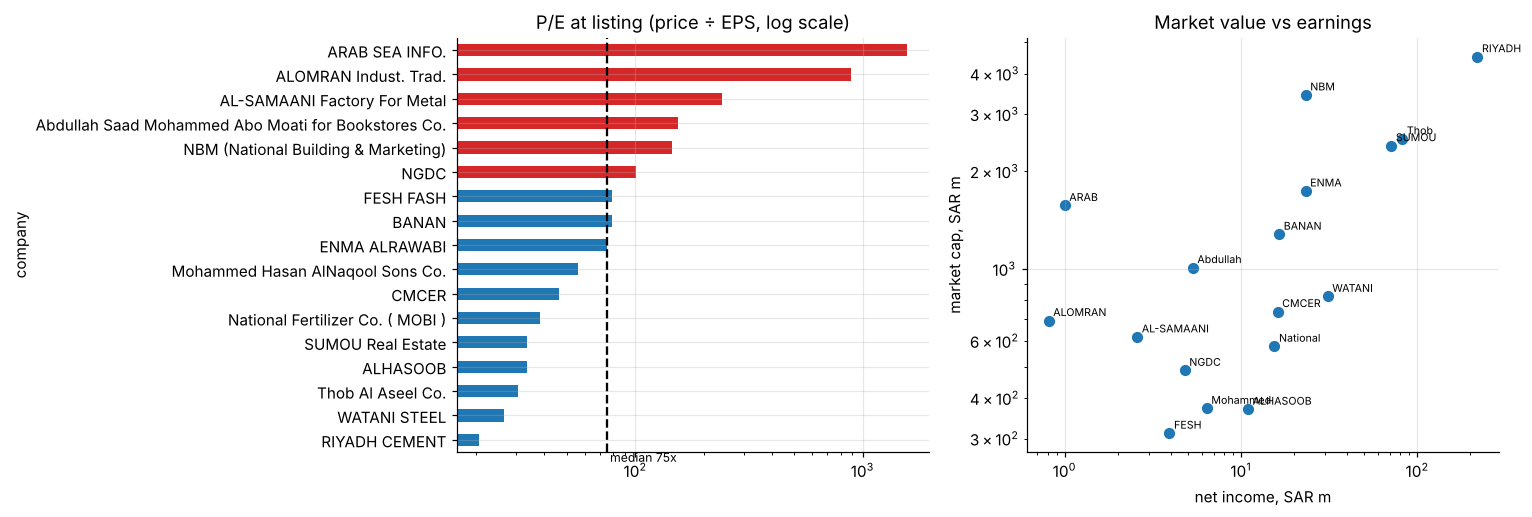

profitable listings: 17 of 18; P/E median 75x, interquartile range 34x-145x


In [2]:
v = n[n.income_m > 0].copy()
v["earnings_yield_%"] = 100 * v.income_m / v.mcap_m
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
s = v.set_index("company").pe_check.sort_values()
s.plot.barh(ax=axes[0], color=np.where(s > 100, "C3", "C0"), logx=True, title="P/E at listing (price ÷ EPS, log scale)")
axes[0].axvline(v.pe_check.median(), c="k", ls="--"); axes[0].text(v.pe_check.median(), -0.9, f" median {v.pe_check.median():.0f}x", fontsize=8)
axes[1].scatter(v.income_m, v.mcap_m, s=40)
for _, r in v.iterrows(): axes[1].annotate(r.company.split()[0][:12], (r.income_m, r.mcap_m), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("net income, SAR m"); axes[1].set_ylabel("market cap, SAR m"); axes[1].set_title("Market value vs earnings")
plt.tight_layout(); plt.savefig(IMG / "valuations.png", bbox_inches="tight"); plt.show()
print(f"profitable listings: {len(v)} of {len(n)}; P/E median {v.pe_check.median():.0f}x, interquartile range {v.pe_check.quantile(.25):.0f}x-{v.pe_check.quantile(.75):.0f}x")

In [3]:
lead = n.groupby("advisor").agg(listings=("company", "size"), total_mcap_m=("mcap_m", "sum"), median_pe=("pe_check", "median")).sort_values("listings", ascending=False)
lead.round(1)

,listings,total_mcap_m,median_pe
advisor,,,
Falcom,10,12956.4,47.3
Al Dukheil Financial Group,3,4419.2,46.4
KASB Capital,2,5010.0,857.4
BMG Group,1,617.5,239.8
DARFIN Capital,1,369.6,33.6
Saudi Kuwait Finance House,1,693.6,889.2


In [4]:
fit = np.polyfit(np.log(v.income_m), np.log(v.mcap_m), 1)
v["fair_mcap"] = np.exp(np.polyval(fit, np.log(v.income_m))); v["premium_%"] = 100 * (v.mcap_m / v.fair_mcap - 1)
print(f"log market cap = {fit[1]:.2f} + {fit[0]:.2f} x log income  (an elasticity below 1 means smaller earners get higher multiples)")
v.sort_values("premium_%", ascending=False)[["company", "income_m", "mcap_m", "pe_check", "premium_%"]].round(1).head(6)

log market cap = 6.11 + 0.33 x log income  (an elasticity below 1 means smaller earners get higher multiples)


,company,income_m,mcap_m,pe_check,premium_%
15,ARAB SEA INFO.,1.0,1570.0,1570.0,248.7
16,NBM (National Building & Marketing),23.3,3440.0,144.8,173.6
5,RIYADH CEMENT,220.0,4512.0,20.5,72.7
17,ALOMRAN Indust. Trad.,0.8,693.6,889.2,65.0
14,ENMA ALRAWABI,23.3,1740.0,75.0,38.4
12,Thob Al Aseel Co.,82.4,2520.0,30.5,32.8


## Findings
* **Check before comparing.** 8 of the 18 compiled listings fail at least one internal consistency test. Examples: ALOMRAN reports two different EPS figures (0.13 and 1.07, a P/E of 889× or 108×); Thob Al Aseel's stated P/E (41.8×) does not equal price ÷ EPS (30.5×); one bookstore company's market cap is 23% above price × shares. Valuations here are recomputed from price, EPS and shares, and the source figures should be confirmed against the prospectus before use.
* **Nomu listings are richly valued:** the median P/E at listing is 75×, with an interquartile range of 34× to 145×. Only RIYADH CEMENT (21×), ALHASOOB (34×) and WATANI STEEL (26×) look like conventional mature-company multiples. One listing was loss-making at listing.
* **Small earners get the highest multiples:** market cap rises with net income at an elasticity of only 0.33, so a company earning 1/10th as much is valued at roughly half, not a tenth. That is typical of growth or scarcity premia in a young market, and of thin free floats.
* **Advisor concentration:** Falcom advised 10 of the 18 listings (SAR 13bn of market value). Advisor-level median P/Es are dominated by single outliers, so they should not be read as an advisor effect.
* **Use:** this kind of screen is the first page of a listing-readiness or IPO-pricing discussion: comparable multiples, data validation and an explicit list of the numbers to verify.